In [7]:
library(dplyr)
## visualization
library(ggplot2)
library(ggplot2)
library(gridExtra)
library(dplyr)
library(ggplot2)
library(cowplot)

In [8]:
setwd("/home/liuxuan/metadata/PRJEB12953")
initial_meta <- read.csv("SraRunTable.csv", header = TRUE)
head(initial_meta)
colnames(initial_meta)

,Run,Assay.Type,AvgSpotLen,Bases,BioProject,BioSample,Bytes,Center.Name,Consent,DATASTORE.filetype,⋯,LibrarySource,Organism,Platform,ReleaseDate,create_date,version,Sample.Name,sample_name,SRA.Study,Submitter_Id
,<chr>,<chr>,<int>,<int>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>,⋯,<chr>,<chr>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>,<chr>
1,ERR1303943,AMPLICON,295,21727417,PRJEB12953,SAMEA3888926,10923248,"SEOUL NATIONAL UNIVERSITY, KOREA",public,"fastq,run.zq,sra",⋯,METAGENOMIC,human oral metagenome,ILLUMINA,2018-01-05T00:00:00Z,2018-01-05T10:22:00Z,1,SAMEA3888926,P001,ERP014487,P001
2,ERR1303944,AMPLICON,295,18315137,PRJEB12953,SAMEA3888927,9323758,"SEOUL NATIONAL UNIVERSITY, KOREA",public,"fastq,run.zq,sra",⋯,METAGENOMIC,human oral metagenome,ILLUMINA,2018-01-05T00:00:00Z,2018-01-05T10:23:00Z,1,SAMEA3888927,P002,ERP014487,P002
3,ERR1303945,AMPLICON,295,16360723,PRJEB12953,SAMEA3888928,8421346,"SEOUL NATIONAL UNIVERSITY, KOREA",public,"fastq,run.zq,sra",⋯,METAGENOMIC,human oral metagenome,ILLUMINA,2018-01-05T00:00:00Z,2018-01-05T10:23:00Z,1,SAMEA3888928,P003,ERP014487,P003
4,ERR1303946,AMPLICON,294,11703414,PRJEB12953,SAMEA3888929,5958136,"SEOUL NATIONAL UNIVERSITY, KOREA",public,"fastq,run.zq,sra",⋯,METAGENOMIC,human oral metagenome,ILLUMINA,2018-01-05T00:00:00Z,2018-01-05T10:23:00Z,1,SAMEA3888929,P004,ERP014487,P004
5,ERR1303947,AMPLICON,295,11096210,PRJEB12953,SAMEA3888930,5608081,"SEOUL NATIONAL UNIVERSITY, KOREA",public,"fastq,run.zq,sra",⋯,METAGENOMIC,human oral metagenome,ILLUMINA,2018-01-05T00:00:00Z,2018-01-05T10:23:00Z,1,SAMEA3888930,P005,ERP014487,P005
6,ERR1303948,AMPLICON,295,9845654,PRJEB12953,SAMEA3888931,4961712,"SEOUL NATIONAL UNIVERSITY, KOREA",public,"fastq,run.zq,sra",⋯,METAGENOMIC,human oral metagenome,ILLUMINA,2018-01-05T00:00:00Z,2018-01-05T10:23:00Z,1,SAMEA3888931,P006,ERP014487,P006


[1] "Run"                    "Assay.Type"             "AvgSpotLen"            
 [4] "Bases"                  "BioProject"             "BioSample"             
 [7] "Bytes"                  "Center.Name"            "Consent"               
[10] "DATASTORE.filetype"     "DATASTORE.provider"     "DATASTORE.region"      
[13] "ENA.FIRST.PUBLIC..run." "ENA_first_public"       "ENA.LAST.UPDATE..run." 
[16] "ENA_last_update"        "Experiment"             "external_id"           
[19] "INSDC_center_alias"     "INSDC_center_name"      "INSDC_first_public"    
[22] "INSDC_last_update"      "INSDC_status"           "Instrument"            
[25] "Library.Name"           "LibraryLayout"          "LibrarySelection"      
[28] "LibrarySource"          "Organism"               "Platform"              
[31] "ReleaseDate"            "create_date"            "version"               
[34] "Sample.Name"            "sample_name"            "SRA.Study"             
[37] "Submitter_Id"

In [9]:
uniform_meta <- data.frame(
    BioProject = initial_meta$BioProject,
    Run = initial_meta$Run,
    sample_name = initial_meta$sample_name,
    Age = NA,
    BMI = NA,
    Sex = NA,
    Region = "V3-V4",
    Platform = initial_meta$Platform,
    Country = NA,
    Site = 'saliva',
    public_time = initial_meta$create_date,
    PCR_primers = 'F: TCGTCGGCAGCGTCAGATGTGTATAAGAGACAGCCTACGGGNGGCWGCAG; R: GTCTCGTGGGCTCGGAGATGTGTATAAGAGACAGGACTACHVGGGTATCTAATCC',
    title = 'Oxidative stress in the oral cavity is driven by individual-specific bacterial communities',
    Disease_study = "NO",
    Status = NA,
    matched_samples = 'NO')
print(length(unique(uniform_meta$Run)))
print(length(unique(uniform_meta$sample_name)))

[1] 228
[1] 228


In [13]:
uniform_meta

BioProject,Run,sample_name,Age,BMI,Sex,Region,Platform,Country,Site,public_time,PCR_primers,title,Disease_study,Status
<chr>,<chr>,<chr>,<lgl>,<lgl>,<lgl>,<chr>,<chr>,<lgl>,<chr>,<chr>,<chr>,<chr>,<chr>,<lgl>
PRJEB12953,ERR1303943,P001,NA,NA,NA,V3-V4,ILLUMINA,NA,saliva,2018-01-05T10:22:00Z,F: TCGTCGGCAGCGTCAGATGTGTATAAGAGACAGCCTACGGGNGGCWGCAG; R: GTCTCGTGGGCTCGGAGATGTGTATAAGAGACAGGACTACHVGGGTATCTAATCC,Oxidative stress in the oral cavity is driven by individual-specific bacterial communities,NO,NA
PRJEB12953,ERR1303944,P002,NA,NA,NA,V3-V4,ILLUMINA,NA,saliva,2018-01-05T10:23:00Z,F: TCGTCGGCAGCGTCAGATGTGTATAAGAGACAGCCTACGGGNGGCWGCAG; R: GTCTCGTGGGCTCGGAGATGTGTATAAGAGACAGGACTACHVGGGTATCTAATCC,Oxidative stress in the oral cavity is driven by individual-specific bacterial communities,NO,NA
PRJEB12953,ERR1303945,P003,NA,NA,NA,V3-V4,ILLUMINA,NA,saliva,2018-01-05T10:23:00Z,F: TCGTCGGCAGCGTCAGATGTGTATAAGAGACAGCCTACGGGNGGCWGCAG; R: GTCTCGTGGGCTCGGAGATGTGTATAAGAGACAGGACTACHVGGGTATCTAATCC,Oxidative stress in the oral cavity is driven by individual-specific bacterial communities,NO,NA
PRJEB12953,ERR1303946,P004,NA,NA,NA,V3-V4,ILLUMINA,NA,saliva,2018-01-05T10:23:00Z,F: TCGTCGGCAGCGTCAGATGTGTATAAGAGACAGCCTACGGGNGGCWGCAG; R: GTCTCGTGGGCTCGGAGATGTGTATAAGAGACAGGACTACHVGGGTATCTAATCC,Oxidative stress in the oral cavity is driven by individual-specific bacterial communities,NO,NA
PRJEB12953,ERR1303947,P005,NA,NA,NA,V3-V4,ILLUMINA,NA,saliva,2018-01-05T10:23:00Z,F: TCGTCGGCAGCGTCAGATGTGTATAAGAGACAGCCTACGGGNGGCWGCAG; R: GTCTCGTGGGCTCGGAGATGTGTATAAGAGACAGGACTACHVGGGTATCTAATCC,Oxidative stress in the oral cavity is driven by individual-specific bacterial communities,NO,NA
PRJEB12953,ERR1303948,P006,NA,NA,NA,V3-V4,ILLUMINA,NA,saliva,2018-01-05T10:23:00Z,F: TCGTCGGCAGCGTCAGATGTGTATAAGAGACAGCCTACGGGNGGCWGCAG; R: GTCTCGTGGGCTCGGAGATGTGTATAAGAGACAGGACTACHVGGGTATCTAATCC,Oxidative stress in the oral cavity is driven by individual-specific bacterial communities,NO,NA
PRJEB12953,ERR1303949,P007,NA,NA,NA,V3-V4,ILLUMINA,NA,saliva,2018-01-05T10:23:00Z,F: TCGTCGGCAGCGTCAGATGTGTATAAGAGACAGCCTACGGGNGGCWGCAG; R: GTCTCGTGGGCTCGGAGATGTGTATAAGAGACAGGACTACHVGGGTATCTAATCC,Oxidative stress in the oral cavity is driven by individual-specific bacterial communities,NO,NA
PRJEB12953,ERR1303950,P008,NA,NA,NA,V3-V4,ILLUMINA,NA,saliva,2018-01-05T10:24:00Z,F: TCGTCGGCAGCGTCAGATGTGTATAAGAGACAGCCTACGGGNGGCWGCAG; R: GTCTCGTGGGCTCGGAGATGTGTATAAGAGACAGGACTACHVGGGTATCTAATCC,Oxidative stress in the oral cavity is driven by individual-specific bacterial communities,NO,NA
PRJEB12953,ERR1303951,P009,NA,NA,NA,V3-V4,ILLUMINA,NA,saliva,2018-01-05T10:24:00Z,F: TCGTCGGCAGCGTCAGATGTGTATAAGAGACAGCCTACGGGNGGCWGCAG; R: GTCTCGTGGGCTCGGAGATGTGTATAAGAGACAGGACTACHVGGGTATCTAATCC,Oxidative stress in the oral cavity is driven by individual-specific bacterial communities,NO,NA


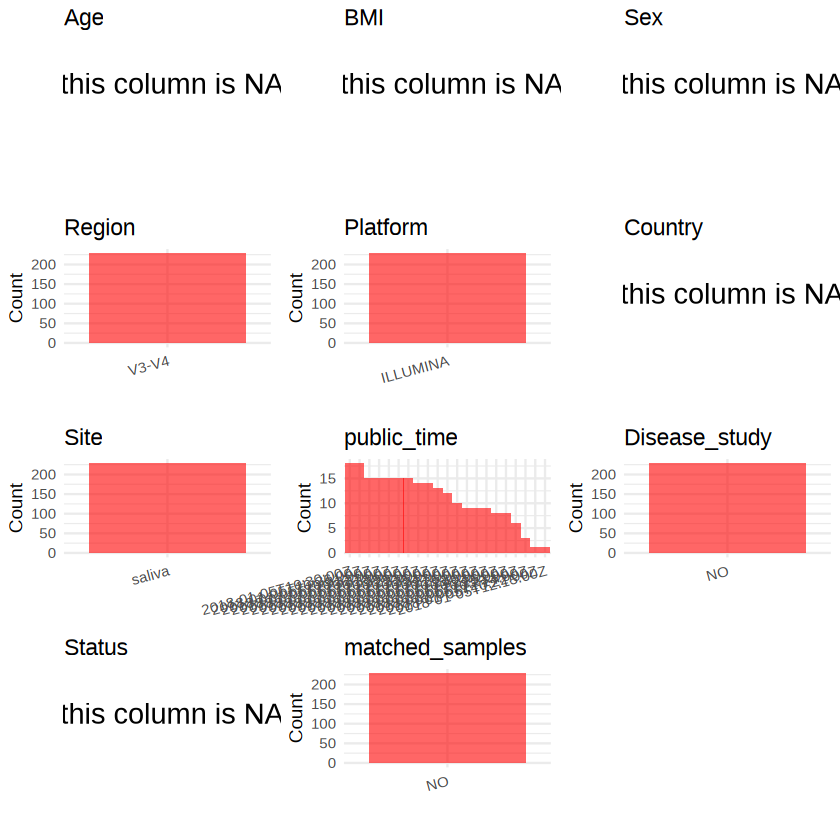

In [11]:
plot_data <- uniform_meta %>%
  select(-BioProject, -Run, -sample_name, -title)

create_simple_plots <- function(data) {
  plots <- list()
  
  for (col in colnames(data)) {
    if (all(is.na(data[[col]]))) {
      p <- ggplot() +
        annotate("text", x = 0.5, y = 0.5, label = "this column is NA", size = 6) +
        labs(title = col) +
        theme_void()
    } else if (is.numeric(data[[col]])) {
      p <- ggplot(data, aes(x = .data[[col]])) +
        geom_histogram(fill = "blue", alpha = 0.6, bins = 20, na.rm = TRUE) +
        labs(title = col) +
        theme_minimal()
    } else {
      count_data <- as.data.frame(table(data[[col]], useNA = "ifany"))
      p <- ggplot(count_data, aes(x = reorder(Var1, -Freq), y = Freq)) +
        geom_col(fill = "red", alpha = 0.6) +
        labs(title = col, x = NULL, y = "Count") +
        theme_minimal() +
        theme(axis.text.x = element_text(angle = 15, hjust = 1))
    }
    plots[[col]] <- p
  }
  return(plots)
}

plots <- create_simple_plots(plot_data)
p <- plot_grid(plots$Age, plots$BMI, plots$Sex, plots$Region, 
               plots$Platform, plots$Country, plots$Site,
               plots$public_time, plots$Disease_study,
               plots$Status, plots$matched_samples, 
               ncol = 3, align = "hv", axis = "lb")
p

In [12]:
uniform_meta <- uniform_meta[, c("BioProject", "Run", "sample_name", "Age", "BMI", "Sex", "Region", "Platform", "Country", "Site", "public_time", "PCR_primers", "title", "Disease_study", "Status")]
write.csv(uniform_meta, file = "/home/liuxuan/metadata/PRJEB20213/metadata.csv", quote = F)